# Train–Validation–Test Split — Multilingual Citizen Feedback ABSA Corpus

**Project:** English–Tagalog–Ilokano E-Governance Citizen Feedback  
**Finalized corpus:** 973 comments and 1,327 aspect-level sentiment annotations  
**Goal:** Prepare stable, non-overlapping splits for subsequent GLOT500-m fine-tuning and evaluation.

### Split design

| Partition | Comment count | Approx. share | Main use |
|---|---:|---:|---|
| Training | 681 | 70% | Model weight updates |
| Validation | 146 | 15% | Hyperparameters, model selection, early stopping |
| Testing | 146 | 15% | Final unseen-data evaluation |

**Critical rule:** The partition unit is the **comment**, not the individual aspect row. Multiple aspects of the same comment *must not be separated*, otherwise the model can see the same text during training and testing. The source contains a unique `text_group_id` per comment; those values are also checked across splits.

The split retains all original annotation labels and uses a deterministic, weighted multi-label balancing procedure to approximate the original distributions of language, sentiment, aspect category, code-switching, and source. It is not a guarantee of representative sampling beyond the collected data.

No data cleaning, normalization of the source annotations, or model training is performed here. Label canonicalization is used only for computing stratification features and diagnostics; CSV exports preserve original labels.

## 1. Imports and reproducibility settings

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import product
import csv
import json
import re
import numpy as np

SEED = 42
SPLIT_NAMES = ('train','val','test')
TARGETS = (681,146,146)  # exactly 70/15/15 to nearest integer for 973 comments

## 2. CSV loading and metadata helpers

In [ ]:
def read_csv(path):
    with Path(path).open('r', encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        return list(reader.fieldnames or []), list(reader)


def write_csv(path, fieldnames, rows):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w', encoding='utf-8-sig', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)


def canon_language(row):
    value=(row.get('primary_language_canonical') or row.get('primary_language') or '').strip()
    return 'Ilokano' if value.casefold() == 'ilocano' else value


def canon_switch(row):
    return (row.get('code_switched_canonical') or row.get('code_switched') or '').strip().title()


def aspect_code(row):
    raw=row.get('aspect_code') or row.get('aspect_category') or ''
    match=re.search(r'A\d{2}',raw)
    return match.group(0) if match else 'Unknown'

## 3. Validate finalized corpus and construct balancing features

In [ ]:
def validate_source(comments, aspects):
    cids=[r['comment_id'].strip() for r in comments]
    aids=[r['aspect_id'].strip() for r in aspects]
    assert len(comments) == 973, f'Expected 973 final comments; got {len(comments)}.'
    assert len(aspects) == 1327, f'Expected 1,327 final aspects; got {len(aspects)}.'
    assert len(set(cids)) == len(cids), 'Duplicate comment IDs in source.'
    assert len(set(aids)) == len(aids), 'Duplicate aspect IDs in source.'
    assert set(r['comment_id'] for r in aspects) == set(cids), 'Aspects/comments not 1-to-many linked.'
    assert all(r.get('model_text','').strip() for r in comments), 'Blank model_text in corpus.'
    assert all(r.get('sentiment','').strip() for r in aspects), 'Blank aspect sentiment.'
    # The corpus has unique normalized text hashes, so exact 681/146/146 comment allocation is possible.
    hashes=[r.get('text_group_id','').strip() or r['comment_id'] for r in comments]
    assert len(set(hashes))==len(hashes), 'Repeated text_group_id: revise to allocate whole text groups.'
    # Some annotation labels are spelled Ilocano in the file; canonicalize ONLY for the split strata.
    assert all(canon_language(r) for r in comments), 'Missing primary language.'


def make_features(comments, aspects):
    bycid=defaultdict(list)
    for a in aspects: bycid[a['comment_id']].append(a)
    langs=sorted(set(canon_language(c) for c in comments))
    sources=sorted(set((c.get('source_type') or 'Unspecified').strip() for c in comments))
    senti=sorted(set(a['sentiment'].strip().title() for a in aspects))
    codes=sorted(set(aspect_code(a) for a in aspects))
    joints=Counter((canon_language(next(c for c in comments if c['comment_id']==a['comment_id'])),a['sentiment'].strip().title()) for a in aspects)
    # Focus joint cell optimization on supported cells; rare cells are still reported, never dropped from data.
    code_senti=Counter((aspect_code(a),a['sentiment'].strip().title()) for a in aspects)

    features=[]
    weights=[]
    def add(f,w):
        features.append(f); weights.append(w)
    add(('SIZE','comment'),5)
    for lang in langs:add(('LANG',lang),3.0)
    for sw in ('Yes','No'):add(('SW',sw),1.7)
    for src in sources:add(('SOURCE',src),0.75)
    for sent in senti:add(('SENT',sent),4.0)
    for code in codes:add(('ASPECT',code),1.65)
    for (lang,sent),num in sorted(joints.items()):
        if num>=8:add(('LANG_SENT',lang+' / '+sent),1.4)
    for (code,sent),num in sorted(code_senti.items()):
        if num>=8:add(('ASPECT_SENT',code+' / '+sent),0.75)
    add(('MULTI_ASPECT','yes'),0.8)
    add(('MIXED_SENTIMENT','yes'),1.5)
    index={f:i for i,f in enumerate(features)}
    X=np.zeros((len(comments),len(features)),dtype=np.float64)
    for i,c in enumerate(comments):
        ann=bycid[c['comment_id']]
        lang=canon_language(c)
        def tally(f,n=1):
            j=index.get(f)
            if j is not None: X[i,j]+=n
        tally(('SIZE','comment'))
        tally(('LANG',lang))
        tally(('SW',canon_switch(c)))
        tally(('SOURCE',(c.get('source_type') or 'Unspecified').strip()))
        for a in ann:
            s=a['sentiment'].strip().title()
            cd=aspect_code(a)
            tally(('SENT',s))
            tally(('ASPECT',cd))
            tally(('LANG_SENT',lang+' / '+s))
            tally(('ASPECT_SENT',cd+' / '+s))
        tally(('MULTI_ASPECT','yes'),int(len(ann)>1))
        tally(('MIXED_SENTIMENT','yes'),int(len({a['sentiment'] for a in ann})>1))
    return features, np.array(weights), X

## 4. Find balanced comment-level partitions

In [ ]:
def pick_split(comments, aspects, seed=SEED, candidates=850, swaps=25000):
    features,weights,X=make_features(comments,aspects)
    n=len(comments)
    sizes=np.array([int(round(n*0.70)),int(round(n*0.15)),0],dtype=int)
    sizes[2]=n-sizes[0]-sizes[1]
    assert tuple(sizes)==TARGETS
    proportions=sizes/n
    total=X.sum(axis=0)
    expected=proportions[:,None]*total[None,:]
    denom=np.maximum(expected,2.0)
    def score(counts):
        # Weighted squared relative-to-expected discrepancy; scale by feature family frequency.
        s=float(np.sum(weights[None,:] * ((counts-expected)**2 / denom)))
        # Ensure every aspect category and sentiment appears in each partition if feasible.
        for j,feat in enumerate(features):
            if feat[0]=='ASPECT' and total[j]>=9:
                s += 15.0 * float(np.sum(counts[:,j]==0))
            if feat[0]=='SENT':
                s += 30.0 * float(np.sum(counts[:,j]==0))
        return s
    rng=np.random.default_rng(seed)
    best_assign=None; best_counts=None; best_score=float('inf')
    for _ in range(candidates):
        order=rng.permutation(n)
        assign=np.empty(n,dtype=np.int8)
        assign[order[:sizes[0]]]=0
        assign[order[sizes[0]:sizes[0]+sizes[1]]]=1
        assign[order[sizes[0]+sizes[1]:]]=2
        counts=np.stack([X[assign==s].sum(axis=0) for s in range(3)],axis=0)
        loss=score(counts)
        if loss<best_score:
            best_score=loss;best_assign=assign.copy();best_counts=counts.copy()
    # Greedy pairwise swap between partitions: never changes the exact comment counts.
    assign=best_assign.copy();counts=best_counts.copy();loss=best_score
    for it in range(swaps):
        a,b=rng.integers(n,size=2)
        sa=int(assign[a]); sb=int(assign[b])
        if sa==sb:continue
        delta=X[b]-X[a]
        after=counts.copy()
        after[sa]+=delta;after[sb]-=delta
        new_score=score(after)
        if new_score < loss - 1e-10:
            assign[a]=sb;assign[b]=sa
            counts=after;loss=new_score
    assignment={c['comment_id']:SPLIT_NAMES[int(s)] for c,s in zip(comments,assign)}
    return assignment,features,counts,loss

## 5. Save the partition manifest and validation reports

In [ ]:
def make_reports(comments,aspects,assign,features,feature_counts,score,outdir):
    bycid=defaultdict(list)
    for a in aspects:bycid[a['comment_id']].append(a)
    lang=Counter()
    sentiment=Counter()
    aspects_cat=Counter()
    code_switch=Counter()
    source=Counter()
    for c in comments:
        sp=assign[c['comment_id']]
        lang[(sp,canon_language(c))]+=1
        code_switch[(sp,canon_switch(c))]+=1
        source[(sp,(c.get('source_type') or 'Unspecified').strip())]+=1
    for a in aspects:
        sp=assign[a['comment_id']]
        sentiment[(sp,a['sentiment'].strip().title())]+=1
        aspects_cat[(sp,aspect_code(a))]+=1
    rows=[]
    metric_families=[('Language (comments)',lang),('Code-switching (comments)',code_switch),
                     ('Source (comments)',source),('Sentiment (aspects)',sentiment),('Aspect category (aspects)',aspects_cat)]
    for family,ctr in metric_families:
        labels=sorted({label for sp,label in ctr})
        for label in labels:
            values=[ctr[(sp,label)] for sp in SPLIT_NAMES]
            total=sum(values)
            rows.append({'family':family,'label':label,'total':total,'train':values[0],'validation':values[1],
                         'test':values[2],'train_pct_of_label':round(100*values[0]/total,2),
                         'validation_pct_of_label':round(100*values[1]/total,2),
                         'test_pct_of_label':round(100*values[2]/total,2)})
    write_csv(outdir/'split_distribution_comparison.csv',list(rows[0].keys()),rows)
    cr=Counter(assign.values())
    ar=Counter(assign[a['comment_id']] for a in aspects)
    sumrows=[]
    for sp in SPLIT_NAMES:
        sumrows.append({'split':sp,'comments':cr[sp],'comments_percentage':round(100*cr[sp]/len(comments),2),
                        'aspect_rows':ar[sp],'aspect_percentage':round(100*ar[sp]/len(aspects),2),
                        'English':lang[(sp,'English')], 'Tagalog':lang[(sp,'Tagalog')],
                        'Ilokano':lang[(sp,'Ilokano')],'Mixed':lang[(sp,'Mixed')],
                        'code_switched_yes':code_switch[(sp,'Yes')],
                        'Positive':sentiment[(sp,'Positive')],'Negative':sentiment[(sp,'Negative')],
                        'Neutral':sentiment[(sp,'Neutral')]})
    write_csv(outdir/'split_summary.csv',list(sumrows[0].keys()),sumrows)
    manifest=[]
    for c in sorted(comments,key=lambda c:c['comment_id']):
        a=bycid[c['comment_id']]
        manifest.append({'comment_id':c['comment_id'],'split':assign[c['comment_id']],
                         'text_group_id':c.get('text_group_id',''),'primary_language':canon_language(c),
                         'code_switched':canon_switch(c),'source_type':c.get('source_type',''),
                         'aspect_count':len(a),'sentiments':'; '.join(sorted({z['sentiment'] for z in a})),
                         'aspect_categories':'; '.join(sorted({aspect_code(z) for z in a}))})
    write_csv(outdir/'comment_split_manifest.csv',list(manifest[0].keys()),manifest)
    ids_by_split={sp:{cid for cid,k in assign.items() if k==sp} for sp in SPLIT_NAMES}
    source_hashes={sp:{c.get('text_group_id') for c in comments if assign[c['comment_id']]==sp} for sp in SPLIT_NAMES}
    model_norm={sp:{' '.join(c['model_text'].lower().split()) for c in comments if assign[c['comment_id']]==sp} for sp in SPLIT_NAMES}
    qc={
        'comment_id_overlap':all(not(ids_by_split[a]&ids_by_split[b]) for a,b in product(SPLIT_NAMES,repeat=2) if a<b),
        'text_group_id_overlap':all(not(source_hashes[a]&source_hashes[b]) for a,b in product(SPLIT_NAMES,repeat=2) if a<b),
        'normalized_text_overlap':all(not(model_norm[a]&model_norm[b]) for a,b in product(SPLIT_NAMES,repeat=2) if a<b),
        'all_comments_assigned_once':len(assign)==len(comments) and all(sum(k in ids_by_split[sp] for sp in SPLIT_NAMES)==1 for k in assign),
        'all_aspects_assigned_once':sum(ar.values())==len(aspects),
        'all_three_sentiments_present_in_each_split':all(all(sentiment[(sp,s)]>0 for s in ('Positive','Neutral','Negative')) for sp in SPLIT_NAMES),
        'all_eleven_aspect_categories_present_in_each_split':all(all(aspects_cat[(sp,f'A{i:02}')]>0 for i in range(1,12)) for sp in SPLIT_NAMES),
    }
    report={'seed':SEED,'comment_split_target':dict(zip(SPLIT_NAMES,TARGETS)),
            'comment_count':len(comments),'aspect_annotation_count':len(aspects),
            'split_sizes':dict(cr),'aspect_row_sizes':dict(ar),
            'grouping':'comment_id + unique text_group_id',
            'balancing':'weighted multi-label optimization at the comment level (language, sentiment, aspect category, code-switching, source, selected joint cells)',
            'objective_value':round(score,4), 'checks':qc}
    (outdir/'split_config_and_checks.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
    return sumrows,report

## 6. Run the split and verify every exported file

In [ ]:
def run_pipeline(data_dir, output_dir, *, seed=SEED, verbose=True):
    data_dir=Path(data_dir);outdir=Path(output_dir);outdir.mkdir(parents=True,exist_ok=True)
    comment_fields,comments=read_csv(data_dir/'corpus_comments.csv')
    aspect_fields,aspects=read_csv(data_dir/'corpus_aspects.csv')
    validate_source(comments,aspects)
    assign,features,feature_counts,score=pick_split(comments,aspects,seed=seed)
    for sp in SPLIT_NAMES:
        write_csv(outdir/f'{sp}_comments.csv',comment_fields,[c for c in comments if assign[c['comment_id']]==sp])
        write_csv(outdir/f'{sp}_aspects.csv',aspect_fields,[a for a in aspects if assign[a['comment_id']]==sp])
    summary,report=make_reports(comments,aspects,assign,features,feature_counts,score,outdir)
    assert all(report['checks'].values()),f"Split quality checks failed: {report['checks']}"
    if verbose:
        print('Reproducible 70/15/15 corpus split, seed=',seed)
        for row in summary:print(row)
        print('Balance score:',round(score,4))
        print('Integrity checks:',report['checks'])
    return summary,report

In [ ]:
from pathlib import Path
DATA_DIR = Path.cwd()
# For Google Colab, upload/extract the two master CSVs into the current working directory.
# For Jupyter/VS Code, place them next to the notebook.
if not (DATA_DIR / 'corpus_comments.csv').exists():
    alternate = Path('/mnt/data/citizen_feedback_split')
    if (alternate / 'corpus_comments.csv').exists():
        DATA_DIR = alternate
if not (DATA_DIR / 'corpus_comments.csv').exists():
    raise FileNotFoundError('Put corpus_comments.csv and corpus_aspects.csv in the working directory.')

summary, quality = run_pipeline(DATA_DIR, DATA_DIR, seed=SEED)
assert all(quality['checks'].values()), 'Split verification did not pass.'
print('All split checks passed. Files saved in:', DATA_DIR.resolve())

Reproducible 70/15/15 corpus split, seed= 42
{'split': 'train', 'comments': 681, 'comments_percentage': 69.99, 'aspect_rows': 928, 'aspect_percentage': 69.93, 'English': 161, 'Tagalog': 329, 'Ilokano': 117, 'Mixed': 74, 'code_switched_yes': 285, 'Positive': 216, 'Negative': 536, 'Neutral': 176}
{'split': 'val', 'comments': 146, 'comments_percentage': 15.01, 'aspect_rows': 200, 'aspect_percentage': 15.07, 'English': 34, 'Tagalog': 71, 'Ilokano': 25, 'Mixed': 16, 'code_switched_yes': 61, 'Positive': 47, 'Negative': 115, 'Neutral': 38}
{'split': 'test', 'comments': 146, 'comments_percentage': 15.01, 'aspect_rows': 199, 'aspect_percentage': 15.0, 'English': 35, 'Tagalog': 70, 'Ilokano': 25, 'Mixed': 16, 'code_switched_yes': 62, 'Positive': 46, 'Negative': 115, 'Neutral': 38}
Balance score: 4.0173
Integrity checks: {'comment_id_overlap': True, 'text_group_id_overlap': True, 'normalized_text_overlap': True, 'all_comments_assigned_once': True, 'all_aspects_assigned_once': True, 'all_three_sen

## 7. Visualize the split composition

Percentages below use the correct denominator: **comments** for language and **aspect annotation rows** for sentiment. The plot uses numbers from the saved split outputs, not a newly generated partition.

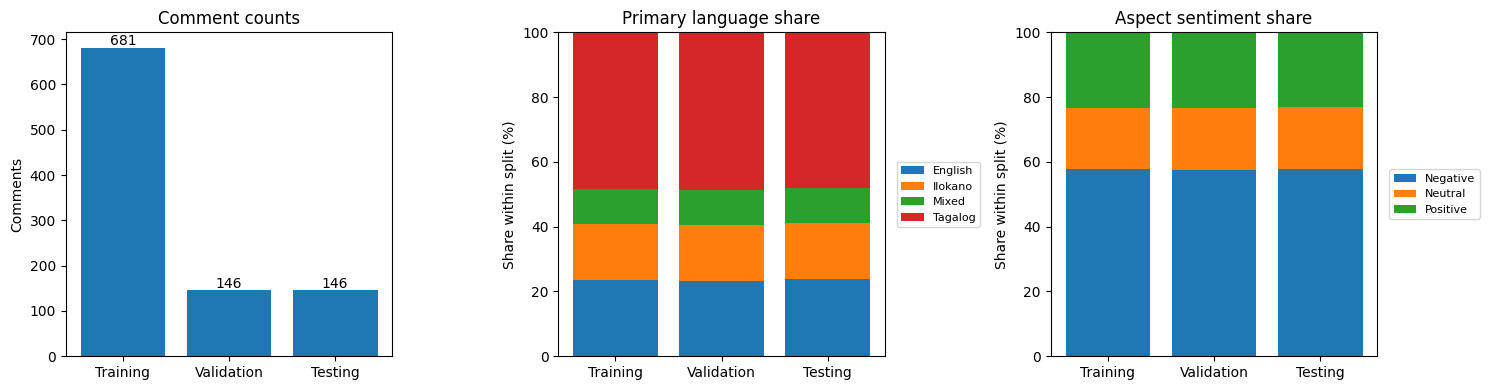

In [ ]:
import matplotlib.pyplot as plt

_, summary_rows = read_csv(DATA_DIR / 'split_summary.csv')
_, distribution_rows = read_csv(DATA_DIR / 'split_distribution_comparison.csv')
partitions=['train','val','test']
part_names=['Training','Validation','Testing']

fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].bar(part_names,[int(r['comments']) for r in summary_rows])
axes[0].set(title='Comment counts',ylabel='Comments')
for i,r in enumerate(summary_rows):
    axes[0].text(i,int(r['comments'])+5,r['comments'],ha='center')

for family, ax, denominator in [
    ('Language (comments)',axes[1],'comments'),
    ('Sentiment (aspects)',axes[2],'aspect_rows')]:
    categories=sorted(set(r['label'] for r in distribution_rows if r['family']==family))
    bottom=np.zeros(3,dtype=float)
    for category in categories:
        row=next(r for r in distribution_rows if r['family']==family and r['label']==category)
        counts=np.array([int(row[p]) if p!='val' else int(row['validation']) for p in partitions])
        denominators=np.array([int(v[denominator]) for v in summary_rows])
        percentages=100*counts/denominators
        ax.bar(part_names,percentages,bottom=bottom,label=category)
        bottom+=percentages
    ax.set(ylim=(0,100),title=('Primary language' if denominator=='comments' else 'Aspect sentiment') + ' share',ylabel='Share within split (%)')
    ax.legend(fontsize=8,loc='center left',bbox_to_anchor=(1.02,0.5))
fig.tight_layout()
plt.show()